In [ ]:
# オートエンコーダー（自己教師あり学習）
# 入力を復元できる潜在空間（LatentSpace）を見つける
# Decoder で Output を再構成する
# Input → Encoder → Latent Space → Decoder → Output

# ノイズの除去や異常検知などに使用される

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
device = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() # Mac用のGPU
    else "cpu"
)
device

'mps'

In [3]:
transform = transforms.Compose([
    transforms.ToTensor()
])

In [6]:
train_dataset = datasets.MNIST(
    root="./data",
    download=True,
    train=True,
    transform=transform
)

In [7]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

In [9]:
# Convolutional Auto Encoder
class ConvAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.en = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )
        self.de = nn.Sequential(
            nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2), # 元に戻すような作業に該当する
            nn.Conv2d(in_channels=16, out_channels=8, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(in_channels=8, out_channels=1, kernel_size=3, padding=1),
            nn.Tanh(),
        )

    def forward(self, x):
        x = self.en(x) # 圧縮された画像
        x = self.de(x) # 再構成された画像
        return x

In [10]:
model = ConvAE()
model.to(device)

ConvAE(
  (en): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
  )
  (de): Sequential(
    (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Upsample(scale_factor=2.0, mode='nearest')
    (3): Conv2d(16, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): Upsample(scale_factor=2.0, mode='nearest')
    (6): Conv2d(8, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): Tanh()
  )
)

In [11]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [13]:
num_epochs = 15
losses = []
for epoch in range(num_epochs):
    running_loss = 0.0
    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        optimizer.zero_grad()
        output = model(imgs)
        loss = criterion(output, imgs)
        running_loss += loss.item()
        loss.backward()
        optimizer.step()
    running_loss /= len(train_loader)
    losses.append(running_loss)
    print("epoch: {}, loss: {}".format(epoch, running_loss))

epoch: 0, loss: 0.013621995810667673
epoch: 1, loss: 0.006117511498183012
epoch: 2, loss: 0.005081876671935121
epoch: 3, loss: 0.004591808508584897
epoch: 4, loss: 0.004302293993284305
epoch: 5, loss: 0.004101359742755691
epoch: 6, loss: 0.0039566862445324655
epoch: 7, loss: 0.003835328062872092
epoch: 8, loss: 0.0037354692464073498
epoch: 9, loss: 0.0036619266462822753
epoch: 10, loss: 0.0036014761339873075
epoch: 11, loss: 0.003548102761556705
epoch: 12, loss: 0.003499418073271712
epoch: 13, loss: 0.0034571147497743366
epoch: 14, loss: 0.0034166671468565863


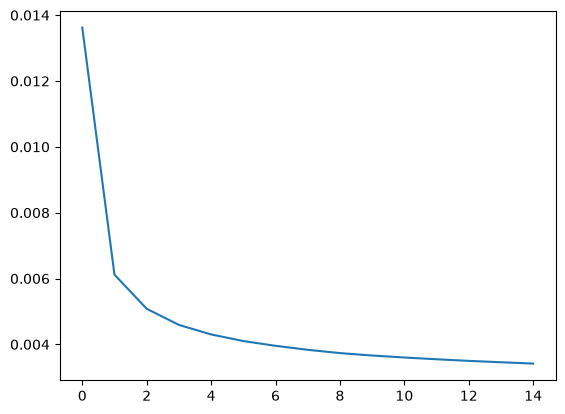

In [15]:
plt.plot(losses)

<Axes: >

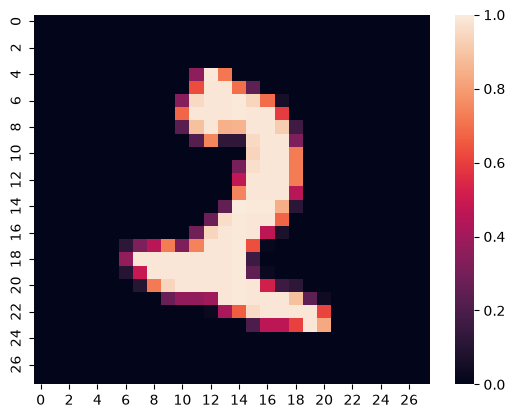

In [14]:
data_iter = iter(train_loader)
imgs, _ = next(data_iter)
img = imgs[0]

img_permute = img.permute(1, 2, 0)
sns.heatmap(img_permute[:, :, 0])

<Axes: >

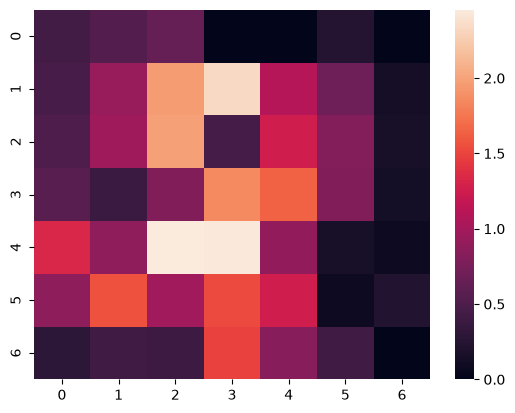

In [16]:
x_en = model.en(imgs.to(device))
x_en2 = x_en[0].permute(1, 2, 0)
# 勾配計算を引き剥がすために、detachが必要
sns.heatmap(x_en2[:, :, 0].detach().to("cpu"))

<Axes: >

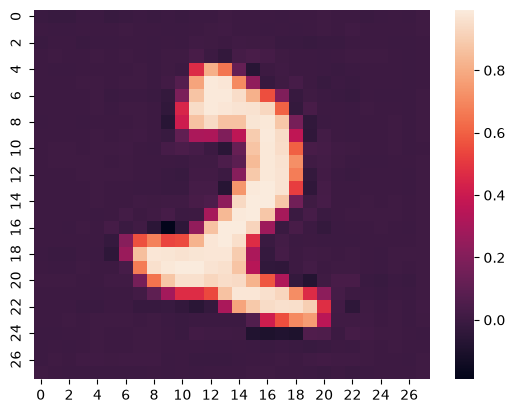

In [17]:
x_ae = model(imgs.to(device))
sns.heatmap(x_ae[0].permute(1, 2, 0).detach().to("cpu")[:, :, 0])